# 07 GLASS Dedicated Pair Plots

Build publication-count/SI plots and category-driver plots only for GLASS pathogen-antibiotic pairs with available SI data.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines import (
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    filter_model_inputs_by_average_amr_publications,
    load_si_and_clean_glass_list,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    save_category_driver_plots,
    save_interesting_si_plots,
    summarize_pathogen_coverage,
)
from amr.pipeline_config import cfg, cfg_path, load_pipeline_config


## Parameters

In [3]:
PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)

OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.output_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.parquet_dir", PROJECT_ROOT)
FIGURE_OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.figure_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ASSETS_DIR = cfg_path(PIPELINE_CONFIG, "paths.assets_dir", PROJECT_ROOT)
YEARLY_SCREENED_PATH = cfg_path(PIPELINE_CONFIG, "paths.yearly_screened", PROJECT_ROOT)
UNIFIED_DECISIONS_PATH = cfg_path(PIPELINE_CONFIG, "paths.unified_decisions", PROJECT_ROOT)
PATHOGEN_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogen_background", PROJECT_ROOT)
ANTIBIOTIC_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_background", PROJECT_ROOT)
ANTIBIOTIC_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_coarsening", PROJECT_ROOT)
DRIVER_CATEGORY_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.driver_category_coarsening", PROJECT_ROOT)

GLASS_XLSX_PATH = cfg_path(PIPELINE_CONFIG, "paths.glass_xlsx", PROJECT_ROOT)
GLASS_CLEANED_PATH = cfg_path(PIPELINE_CONFIG, "paths.glass_cleaned", PROJECT_ROOT)
BACTERIA_SYNONYM_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogens", PROJECT_ROOT)
ANTIBIOTIC_SYNONYM_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_synonyms", PROJECT_ROOT)

ANTIBIOTIC_ANALYSIS_LEVEL = cfg(PIPELINE_CONFIG, "glass_plots.antibiotic_analysis_level")
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
GLASS_SI_PLOT_DIR = FIGURE_OUTPUT_DIR / "glass_yearly_si_plots"
GLASS_DRIVER_PLOT_DIR = FIGURE_OUTPUT_DIR / "glass_yearly_si_driver_plots"

# Reuse SI fit window settings so GLASS plots stay aligned with notebook 05 outputs.
FIT_START_YEAR = cfg(PIPELINE_CONFIG, "si.fit_start_year")
FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.fit_end_year")
CURVE_FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.curve_fit_end_year")
NUM_FUTURE_YEARS = cfg(PIPELINE_CONFIG, "glass_plots.num_future_years")
PLOT_END_YEAR = CURVE_FIT_END_YEAR + NUM_FUTURE_YEARS
MIN_TOTAL_AMR_PUBLICATIONS = cfg(PIPELINE_CONFIG, "glass_plots.min_tot_amr_publications")
MIN_AMR_PAIR_PUBLICATION_COUNT = cfg(PIPELINE_CONFIG, "si.min_amr_pair_publication_count")

LOESS_FRAC = cfg(PIPELINE_CONFIG, "si.loess_frac")
LOESS_DEGREE = cfg(PIPELINE_CONFIG, "si.loess_degree")
TAIL_DAMPING_YEARS = cfg(PIPELINE_CONFIG, "si.tail_damping_years")
FILL_MISSING_AMR_COUNTS_WITH_ZERO = cfg(PIPELINE_CONFIG, "si.fill_missing_amr_counts_with_zero")

CATEGORY_INCLUDE_DECISIONS = tuple(cfg(PIPELINE_CONFIG, "glass_plots.category_include_decisions"))
DRIVER_CATEGORY_LEVEL = cfg(PIPELINE_CONFIG, "glass_plots.driver_category_level")
DRIVER_LOOKBACK_YEARS = cfg(PIPELINE_CONFIG, "glass_plots.driver_lookback_years")
FIGURE_FORMAT = cfg(PIPELINE_CONFIG, "glass_plots.figure_format")
DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "glass_plots.display_plots")
MAX_DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "glass_plots.max_display_plots")
MAX_GLASS_PLOTS = cfg(PIPELINE_CONFIG, "glass_plots.max_glass_plots")


## Load Inputs

In [4]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)

yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_unfiltered_df = yearly_screened_model_df.copy()
yearly_screened_model_df, unified_decisions_model_df, pair_publication_rates = filter_model_inputs_by_average_amr_publications(
    yearly_screened_model_df=yearly_screened_model_df,
    unified_decisions_model_df=unified_decisions_model_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    min_total_amr_publications=MIN_TOTAL_AMR_PUBLICATIONS,
)

pathogen_filter_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_unfiltered_df,
    modeled_df=yearly_screened_model_df,
    source_label="model input before publication filter",
    modeled_label="model input after publication filter",
)
display(pathogen_filter_summary_df.query("status != 'present_in_both'"))

if not YEARLY_SCREENED_PATH.exists():
    raise FileNotFoundError(
        f"Missing {YEARLY_SCREENED_PATH}. Run notebook 04 to create screened AMR pairs first."
    )

si_cache_is_fresh = YEARLY_SI_PATH.exists() and YEARLY_SI_PATH.stat().st_mtime >= YEARLY_SCREENED_PATH.stat().st_mtime
if si_cache_is_fresh:
    si_df = pd.read_parquet(YEARLY_SI_PATH)
    cached_threshold = si_df.get("min_amr_pair_publication_count", pd.Series(dtype=float))
    cached_threshold = float(cached_threshold.dropna().iloc[0]) if not cached_threshold.dropna().empty else None
    si_cache_is_fresh = cached_threshold == float(MIN_AMR_PAIR_PUBLICATION_COUNT)
    if si_cache_is_fresh:
        print(f"Loaded SI rows: {len(si_df):,} from {YEARLY_SI_PATH}")
    else:
        print("Rebuilding SI because min_amr_pair_publication_count changed.")
if not si_cache_is_fresh:
    if YEARLY_SI_PATH.exists():
        print(f"Rebuilding SI because the cached output is stale or its threshold differs from the configured value.")
    si_df, pooled_model, design_columns = build_yearly_si_dataset(
        yearly_screened_model_df,
        pathogen_bg_df,
        antibiotic_bg_model_df,
        min_amr_pair_publication_count=MIN_AMR_PAIR_PUBLICATION_COUNT,
        output_path=YEARLY_SI_PATH,
    )
    print(f"Built SI rows: {len(si_df):,} and saved to {YEARLY_SI_PATH}")

si_pathogen_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_df,
    modeled_df=si_df,
    source_label="filtered model input",
    modeled_label="yearly SI output",
)
display(si_pathogen_summary_df.query("status != 'present_in_both'"))

_, glass_pairs_df = load_si_and_clean_glass_list(
    YEARLY_SI_PATH,
    GLASS_XLSX_PATH,
    bacteria_synonym_path=BACTERIA_SYNONYM_PATH,
    antibiotic_synonym_path=ANTIBIOTIC_SYNONYM_PATH,
    antibiotic_coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    glass_cleaned_path=GLASS_CLEANED_PATH,
)

display(glass_pairs_df.head())


yearly_screened rows: 19,322
yearly_screened unique pathogens: 48
yearly_screened unique antibiotics: 196
yearly_screened year range: 2000 - 2026
pathogen bg rows: 1,296
antibiotic bg rows: 5,319
unified decision rows available for driver analysis: 161,140
Antibiotic analysis level: individual antibiotic.
model yearly rows: 19,322
model pathogen-antibiotic rows: 2,685
model antibiotic values: 196
model antibiotic background rows: 5,319
model unified decision rows: 161,140
AMR publication filter: kept 74 / 2,685 pairs with >= 5 publications/year on average from 2000 to 2023.
model input before publication filter pathogens: 48
model input after publication filter pathogens: 14
Pathogens present in model input before publication filter but absent from model input after publication filter: 34
Aggregatibacter actinomycetemcomitans, Bacillus anthracis, Bordetella pertussis, Borrelia burgdorferi, Brucella melitensis, Burkholderia cepacia, Burkholderia pseudomallei, Chlamydia pneumoniae, Chlam

,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status
0,Aggregatibacter actinomycetemcomitans,77,26,19,0.0,0.0,0.0,True,False,missing_from_modeled
1,Bacillus anthracis,47,31,31,0.0,0.0,0.0,True,False,missing_from_modeled
2,Bordetella pertussis,65,62,23,0.0,0.0,0.0,True,False,missing_from_modeled
3,Borrelia burgdorferi,24,14,16,0.0,0.0,0.0,True,False,missing_from_modeled
4,Brucella melitensis,112,83,30,0.0,0.0,0.0,True,False,missing_from_modeled
5,Burkholderia cepacia,182,97,42,0.0,0.0,0.0,True,False,missing_from_modeled
6,Burkholderia pseudomallei,131,95,35,0.0,0.0,0.0,True,False,missing_from_modeled
7,Chlamydia pneumoniae,29,8,20,0.0,0.0,0.0,True,False,missing_from_modeled
8,Chlamydia trachomatis,90,28,31,0.0,0.0,0.0,True,False,missing_from_modeled
9,Clostridioides difficile,483,644,74,0.0,0.0,0.0,True,False,missing_from_modeled


Loaded SI rows: 6,601 from /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/yearly_si.parquet
filtered model input pathogens: 14
yearly SI output pathogens: 27
Pathogens present in yearly SI output but absent from filtered model input: 13
Clostridioides difficile, Clostridium perfringens, Cutibacterium acnes, Haemophilus influenzae, Listeria monocytogenes, Mycobacterium abscessus, Shigella flexneri, Stenotrophomonas maltophilia, Streptococcus agalactiae, Streptococcus pyogenes, Vibrio cholerae, Vibrio parahaemolyticus, Yersinia enterocolitica


,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status
0,Clostridioides difficile,0.0,0.0,0.0,128,447,6,False,True,only_in_modeled
1,Clostridium perfringens,0.0,0.0,0.0,17,32,1,False,True,only_in_modeled
2,Cutibacterium acnes,0.0,0.0,0.0,61,100,3,False,True,only_in_modeled
3,Haemophilus influenzae,0.0,0.0,0.0,190,367,8,False,True,only_in_modeled
4,Listeria monocytogenes,0.0,0.0,0.0,84,176,4,False,True,only_in_modeled
5,Mycobacterium abscessus,0.0,0.0,0.0,30,71,2,False,True,only_in_modeled
6,Shigella flexneri,0.0,0.0,0.0,92,174,4,False,True,only_in_modeled
7,Stenotrophomonas maltophilia,0.0,0.0,0.0,48,122,2,False,True,only_in_modeled
8,Streptococcus agalactiae,0.0,0.0,0.0,124,367,5,False,True,only_in_modeled
9,Streptococcus pyogenes,0.0,0.0,0.0,51,138,2,False,True,only_in_modeled


Loaded SI rows: 6,601 from /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/yearly_si.parquet
Pathogens: 27; antibiotics/levels: 65
Saved cleaned GLASS rows: 89 to /Users/f.costa/Code/Antimicrobial-Resistance/assets/glass_amr_cleaned.csv


,raw_pathogen,raw_antibiotic,pathogen,antibiotic,pathogen_standardized,antibiotic_standardized,Class,Simplified categories,High level categories,Origin
0,Acinetobacter spp.,amikacin,Acinetobacter baumannii,Amikacin,True,True,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
1,Acinetobacter spp.,Colistin,Acinetobacter baumannii,Colistin,True,False,Polymyxins,Miscellaneous,Other,Naturally occurring/modified
2,Acinetobacter spp.,doripenem,Acinetobacter baumannii,Doripenem,True,True,Carbapenems,Penems/Carbapenems,Beta lactam and related,Naturally occurring/modified
3,Acinetobacter spp.,Gentamicin,Acinetobacter baumannii,Gentamicin,True,False,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
4,Acinetobacter spp.,Imipenem,Acinetobacter baumannii,Imipenem/cilastatin,True,True,Carbapenems,Penems/Carbapenems,Beta lactam and related,Naturally occurring/modified


## Keep GLASS Pairs With SI Data

In [5]:
si_pairs_df = si_df[["pathogen", "antibiotic"]].drop_duplicates()
glass_candidate_pairs_df = glass_pairs_df[["pathogen", "antibiotic"]].drop_duplicates()

glass_available_pairs_df = (
    glass_candidate_pairs_df.merge(si_pairs_df, on=["pathogen", "antibiotic"], how="inner")
    .sort_values(["pathogen", "antibiotic"])
    .reset_index(drop=True)
)

latest_counts_df = (
    si_df.sort_values("year")
    .groupby(["pathogen", "antibiotic"], as_index=False)
    .tail(1)[["pathogen", "antibiotic", "year", "count", "SI"]]
    .rename(columns={"year": "latest_year", "count": "latest_count", "SI": "latest_SI"})
)

glass_plot_pairs_df = (
    glass_available_pairs_df.merge(latest_counts_df, on=["pathogen", "antibiotic"], how="left")
    .sort_values(["latest_count", "pathogen", "antibiotic"], ascending=[False, True, True])
    .reset_index(drop=True)
)
if MAX_GLASS_PLOTS is not None:
    glass_plot_pairs_df = glass_plot_pairs_df.head(int(MAX_GLASS_PLOTS)).copy()

print(f"GLASS candidate pairs: {len(glass_candidate_pairs_df):,}")
print(f"GLASS pairs with SI data: {len(glass_available_pairs_df):,}")
print(f"GLASS pairs selected for plotting: {len(glass_plot_pairs_df):,}")
display(glass_plot_pairs_df.head(30))

GLASS candidate pairs: 89
GLASS pairs with SI data: 56
GLASS pairs selected for plotting: 56


,pathogen,antibiotic,latest_year,latest_count,latest_SI
0,Acinetobacter baumannii,Colistin,2026,28,0.626829
1,Escherichia coli,Colistin,2026,27,0.456512
2,Klebsiella pneumoniae,Meropenem,2026,24,0.503814
3,Klebsiella pneumoniae,Colistin,2026,23,0.569604
4,Escherichia coli,Meropenem,2026,22,0.287563
5,Escherichia coli,Ciprofloxacin,2026,21,0.487971
6,Escherichia coli,Cefotaxime,2026,18,0.556449
7,Klebsiella pneumoniae,Ceftazidime,2026,18,0.617589
8,Salmonella enterica,Ciprofloxacin,2026,17,0.551990
9,Pseudomonas aeruginosa,Colistin,2026,16,0.259648


## Build Category Driver Inputs

In [6]:
category_counts_df, glass_with_drivers_df = build_si_driver_analysis(
    interesting_df=glass_plot_pairs_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=CURVE_FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=None,
)

driver_pairs_df = glass_plot_pairs_df.merge(
    category_counts_df[["pathogen", "antibiotic"]].drop_duplicates(),
    on=["pathogen", "antibiotic"],
    how="inner",
)

print(f"Category-count rows: {len(category_counts_df):,}")
print(f"GLASS pairs with category-driver data: {len(driver_pairs_df):,}")
display(glass_with_drivers_df.head(30))

Saved SI driver explanations to None
Category-count rows: 3,850
GLASS pairs with category-driver data: 31


,pathogen,antibiotic,latest_year,latest_count,latest_SI,driver_recent_total,driver_previous_total,driver_count_change,driver_dominant_category,driver_dominant_category_count,driver_fastest_growing_category,driver_fastest_growing_category_change,driver_weak_signal_share,driver_target_pair_supported_share,driver_target_pair_supported_count,driver_target_pair_unsupported_count
0,Acinetobacter baumannii,Colistin,2026,28,0.626829,158,104,54,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,79,OTHER,0.056719,0.000000,1.0,158,0
1,Escherichia coli,Colistin,2026,27,0.456512,359,212,147,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,188,SURVEILLANCE,0.010419,0.000000,1.0,359,0
2,Klebsiella pneumoniae,Meropenem,2026,24,0.503814,188,71,117,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,109,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.129083,0.000000,1.0,188,0
3,Klebsiella pneumoniae,Colistin,2026,23,0.569604,230,100,130,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,124,SURVEILLANCE,0.074783,0.000000,1.0,230,0
4,Escherichia coli,Meropenem,2026,22,0.287563,159,79,80,SURVEILLANCE,90,SURVEILLANCE,0.021734,0.000000,1.0,159,0
5,Escherichia coli,Ciprofloxacin,2026,21,0.487971,227,183,44,SURVEILLANCE,166,SURVEILLANCE,0.004502,0.004405,1.0,227,0
6,Escherichia coli,Cefotaxime,2026,18,0.556449,192,135,57,SURVEILLANCE,138,SURVEILLANCE,0.037269,0.005208,1.0,192,0
7,Klebsiella pneumoniae,Ceftazidime,2026,18,0.617589,139,30,109,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,95,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.250120,0.000000,1.0,139,0
8,Salmonella enterica,Ciprofloxacin,2026,17,0.551990,138,105,33,SURVEILLANCE,100,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.020497,0.000000,1.0,138,0
9,Pseudomonas aeruginosa,Colistin,2026,16,0.259648,112,59,53,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,60,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.230630,0.000000,1.0,112,0


## Save Dedicated Plots

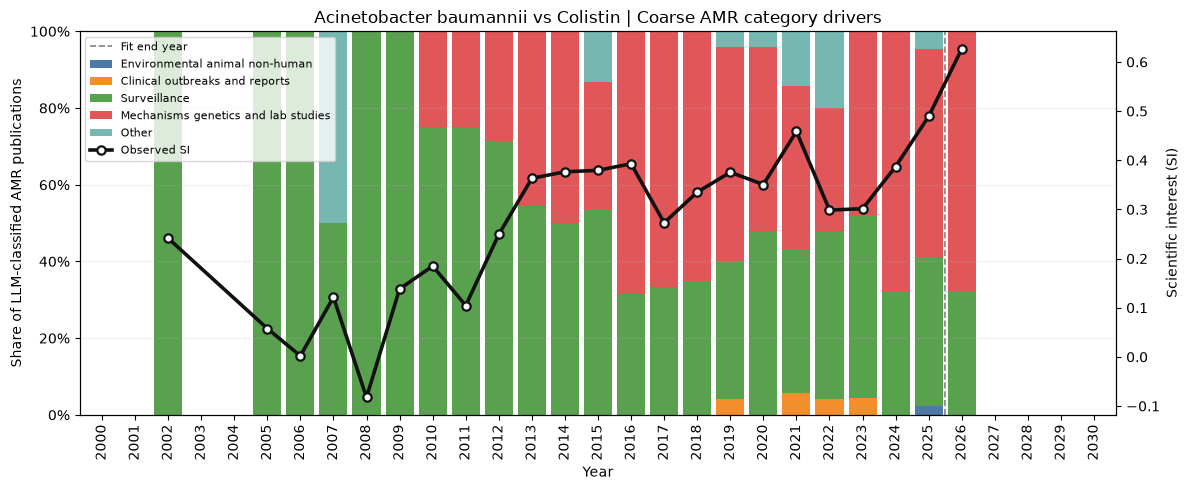

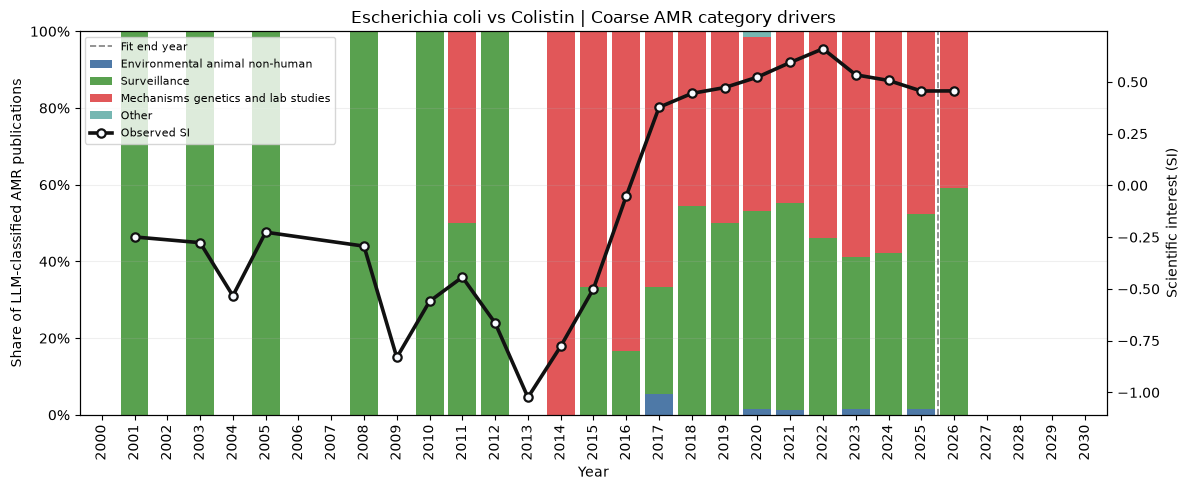

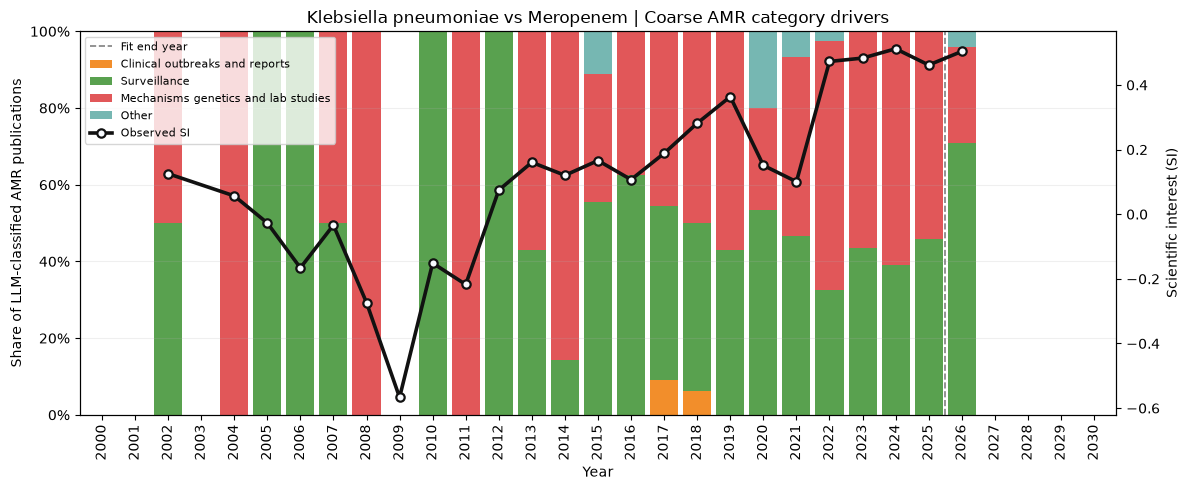

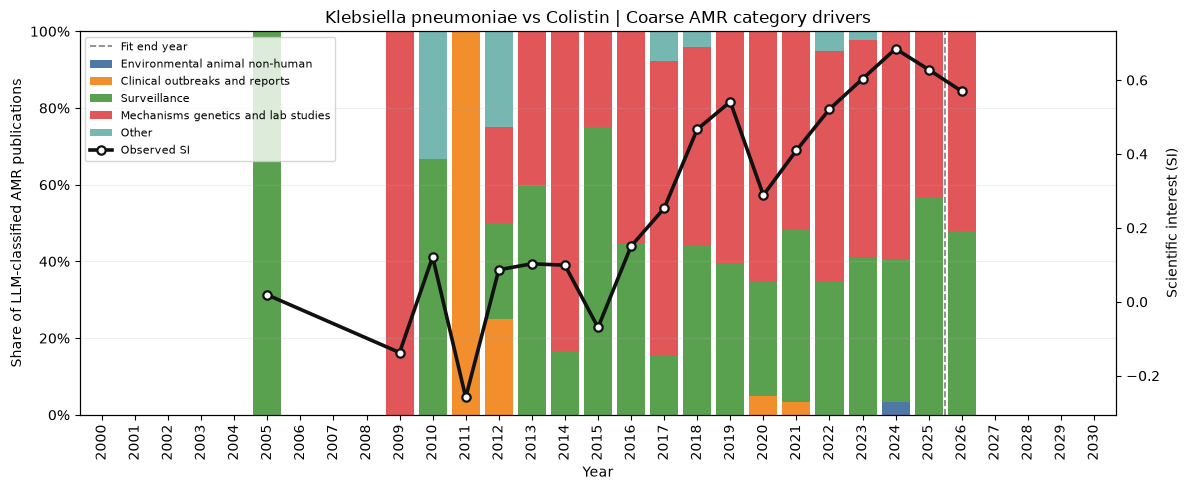

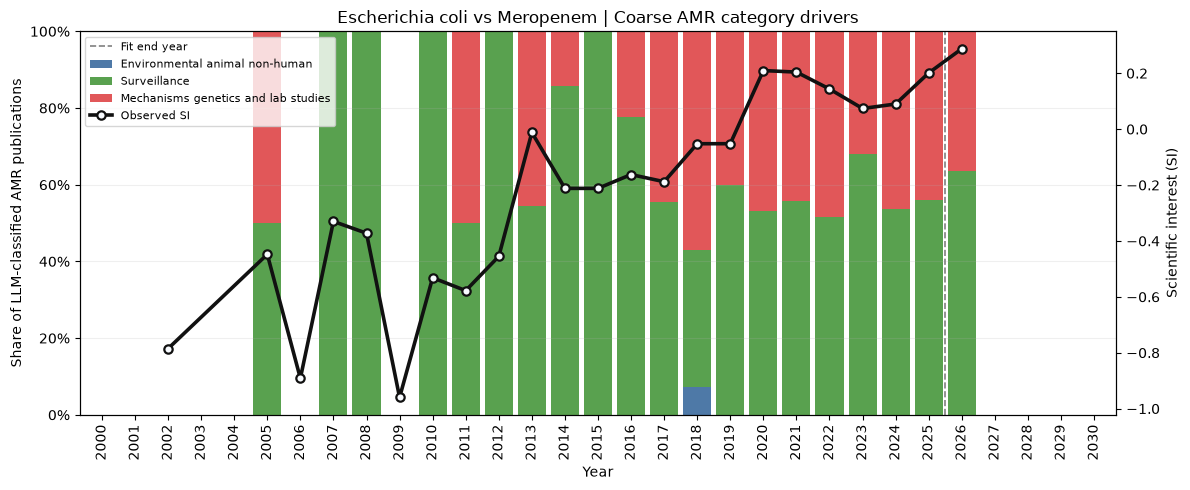

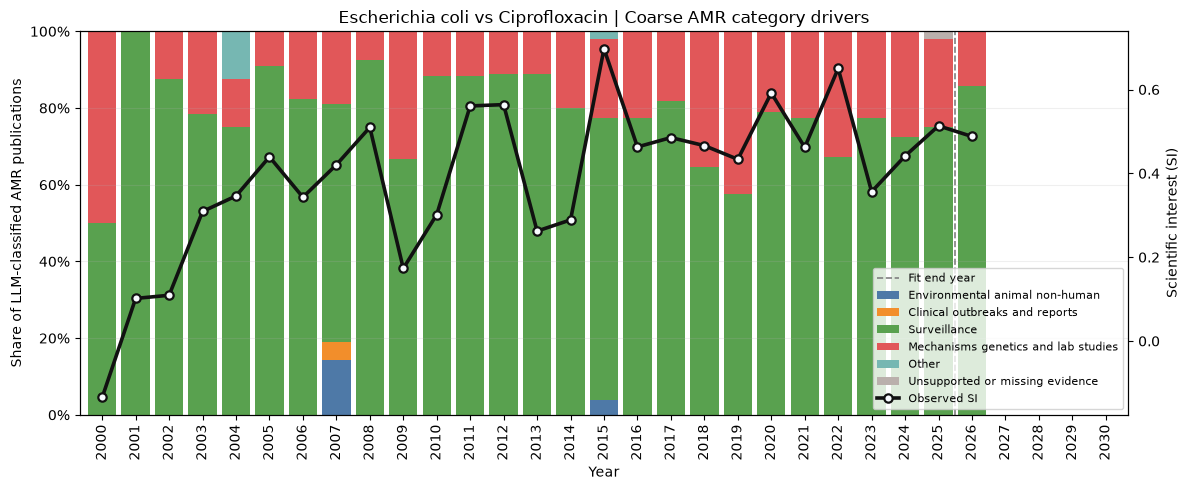

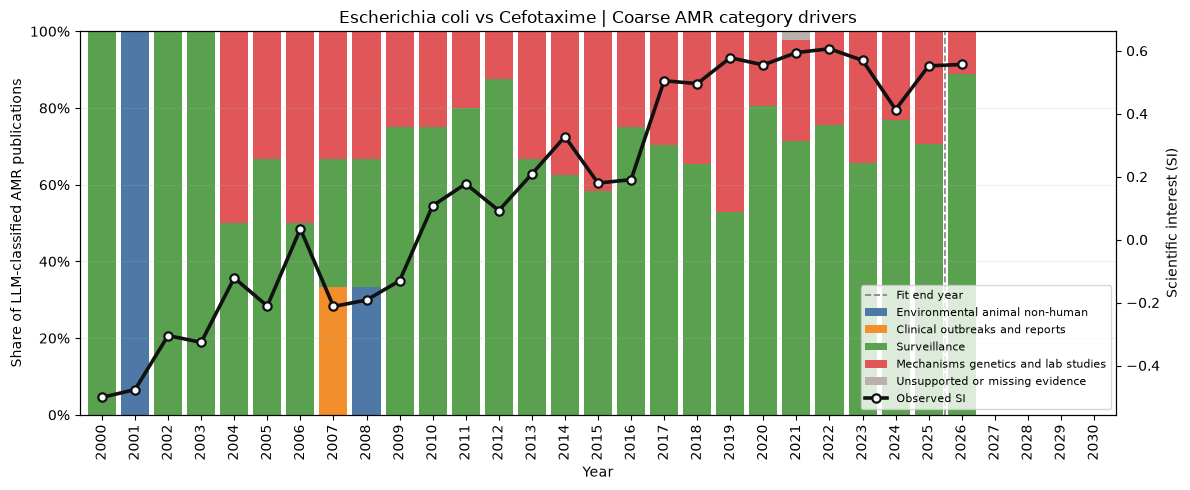

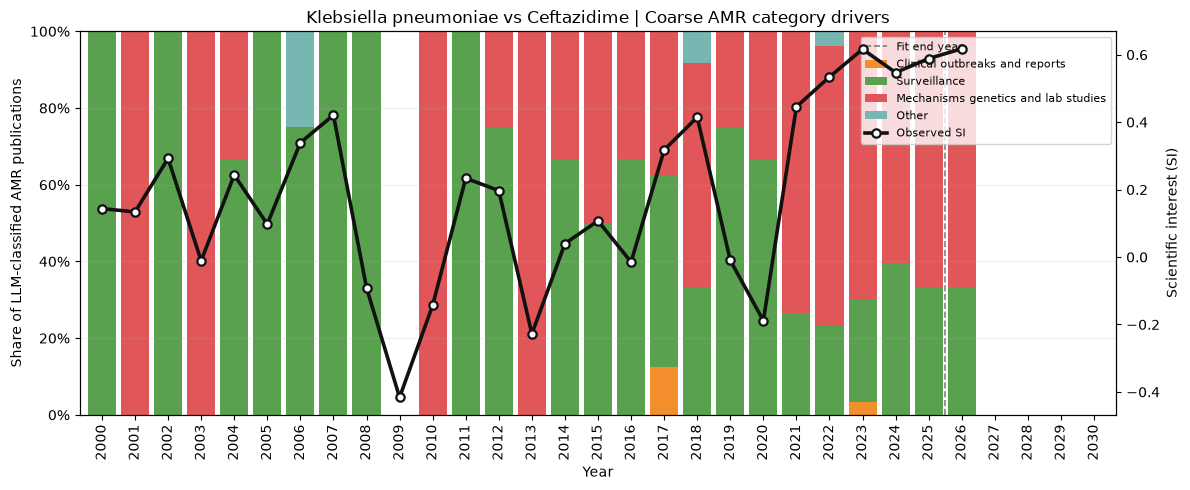

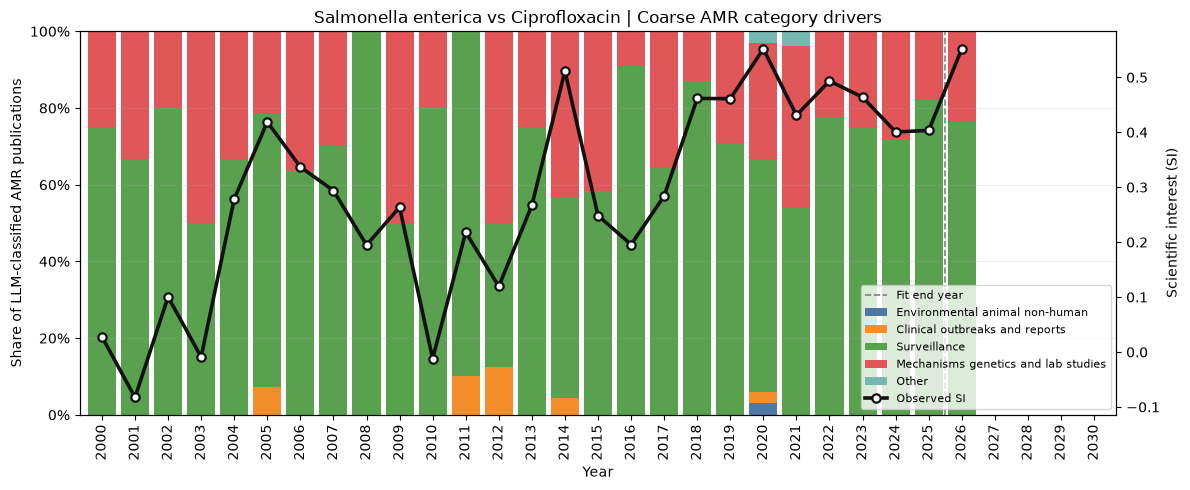

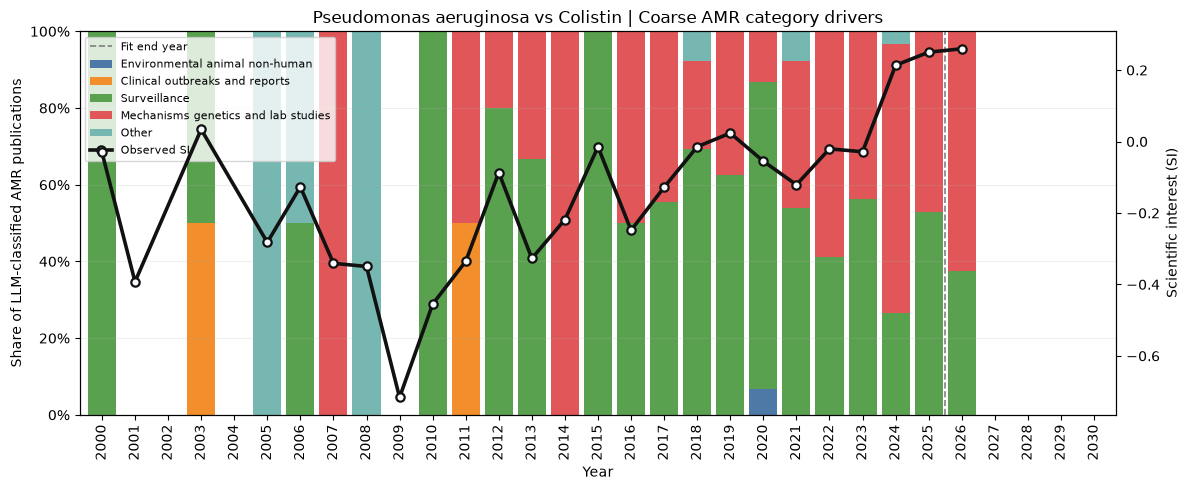

Saved 31 coarse category driver plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/glass_yearly_si_driver_plots
Displayed 10 category driver plots inline.
Saved GLASS driver plots: 31 -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/glass_yearly_si_driver_plots


In [7]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    si_df=si_df,
    interesting_df=driver_pairs_df,
    output_dir=GLASS_DRIVER_PLOT_DIR,
    start_year=FIT_START_YEAR,
    end_year=PLOT_END_YEAR,
    fit_end_year=CURVE_FIT_END_YEAR,
    max_plots=len(driver_pairs_df),
    figure_format=FIGURE_FORMAT,
    driver_category_level=DRIVER_CATEGORY_LEVEL,
    category_coarsening_path=DRIVER_CATEGORY_COARSENING_PATH,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)

print(f"Saved GLASS driver plots: {saved_driver_plots:,} -> {GLASS_DRIVER_PLOT_DIR}")

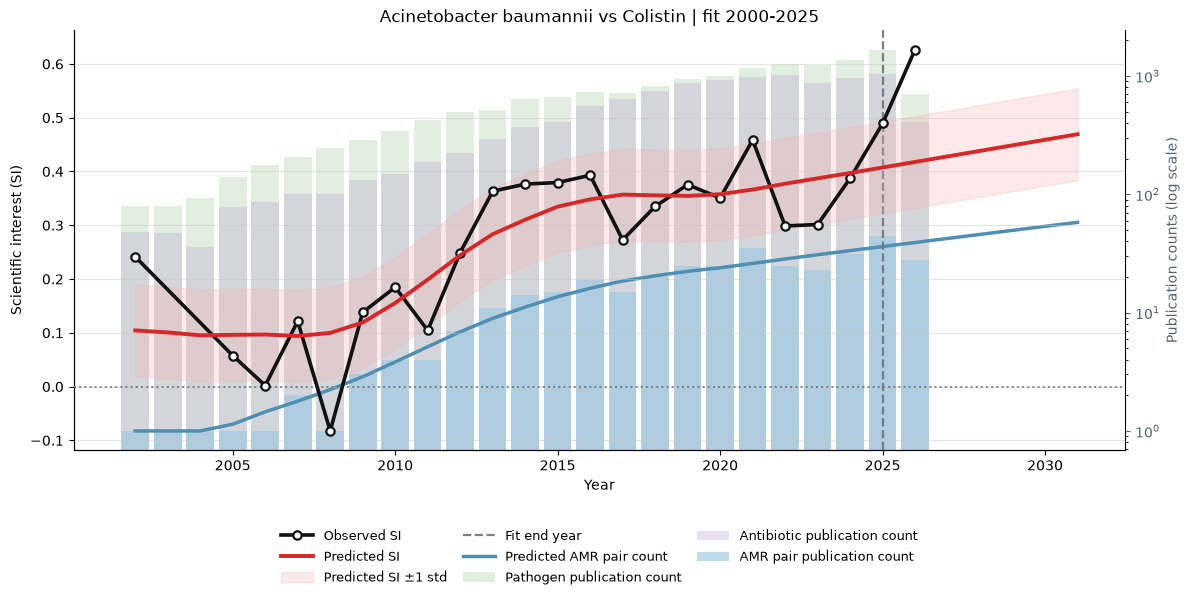

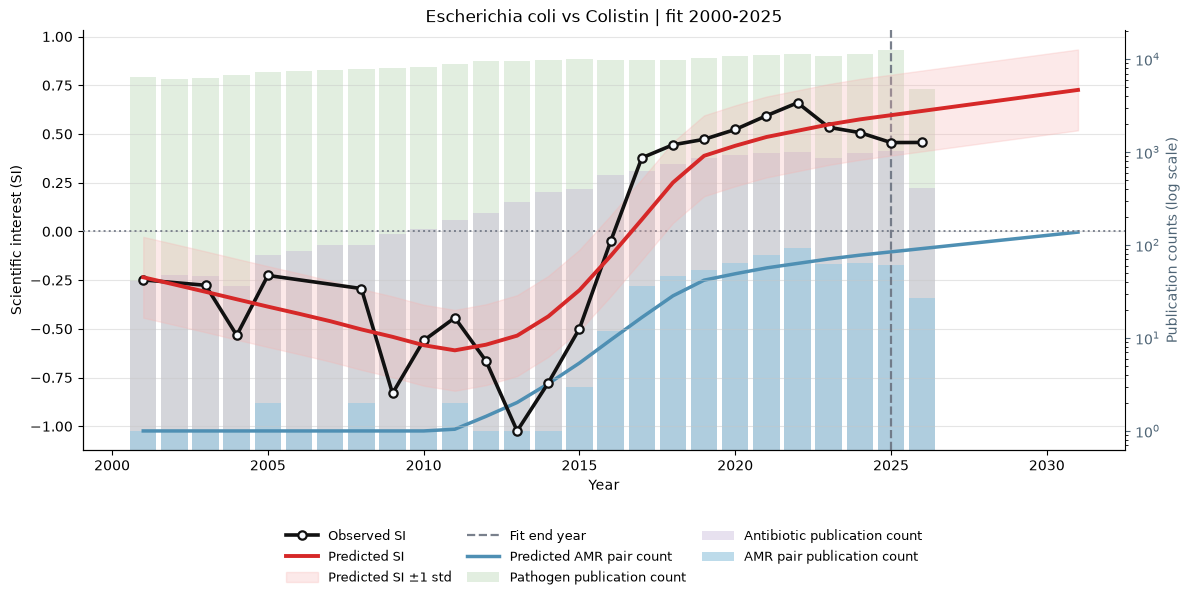

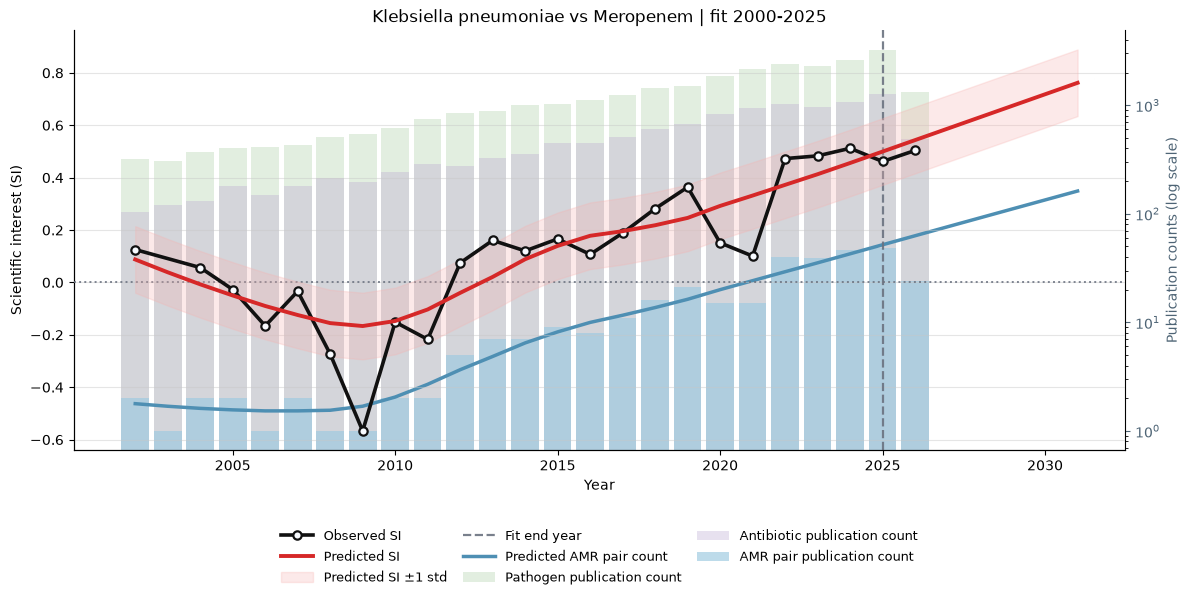

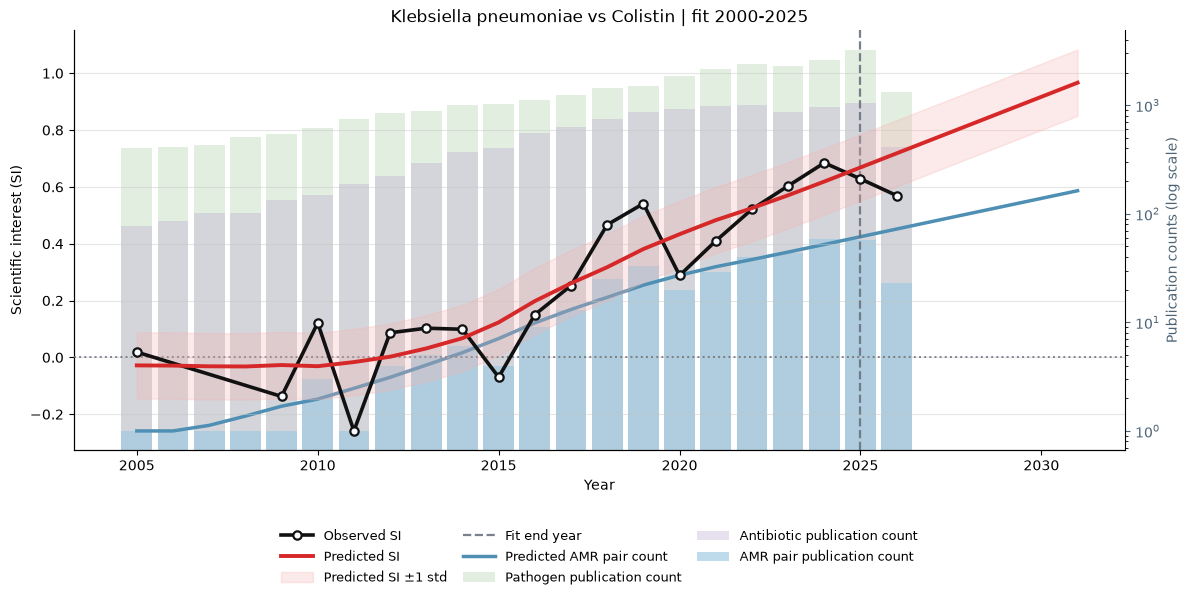

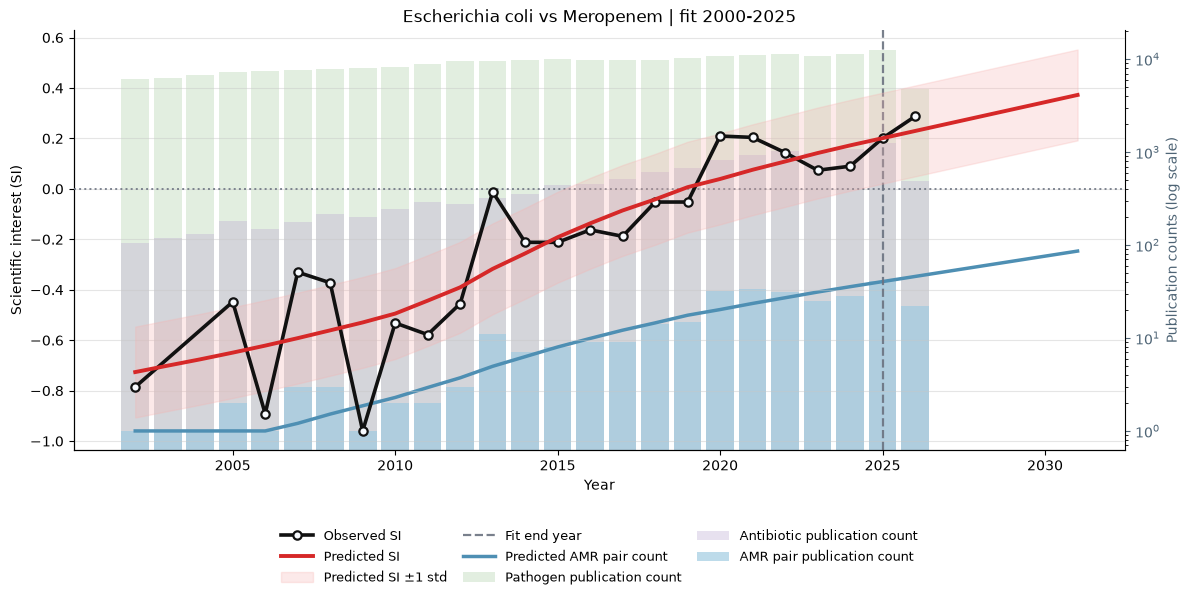

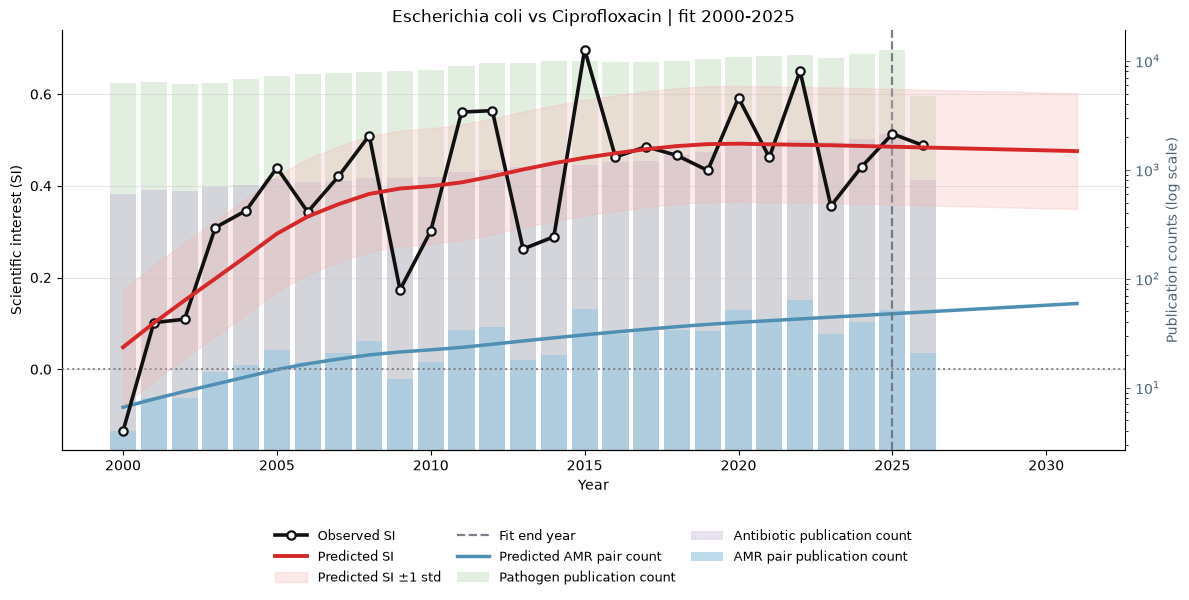

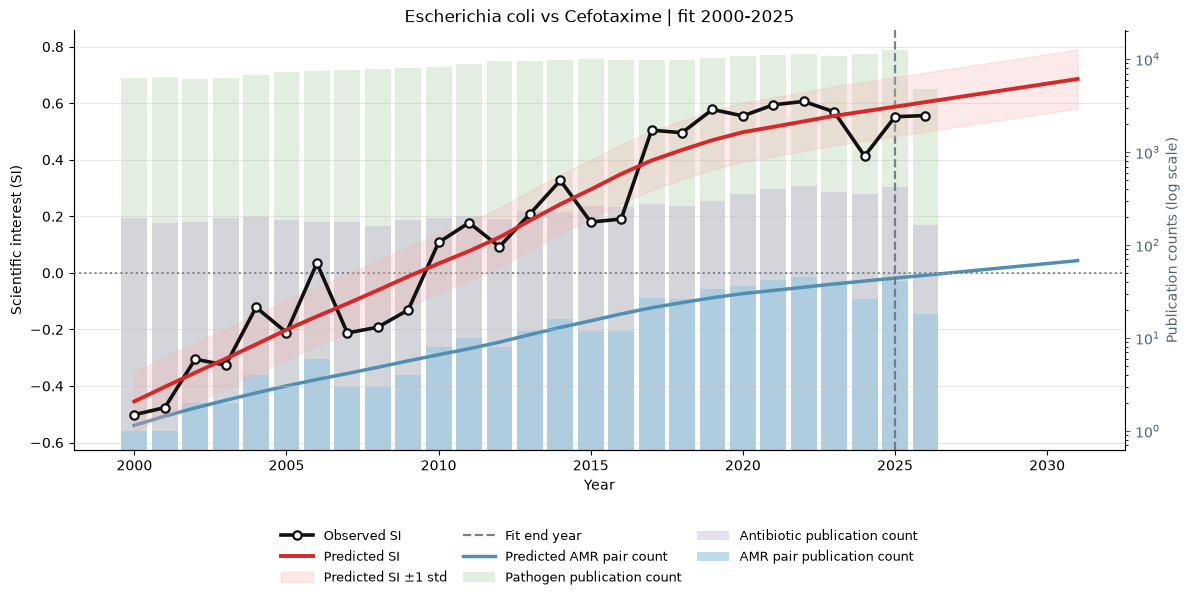

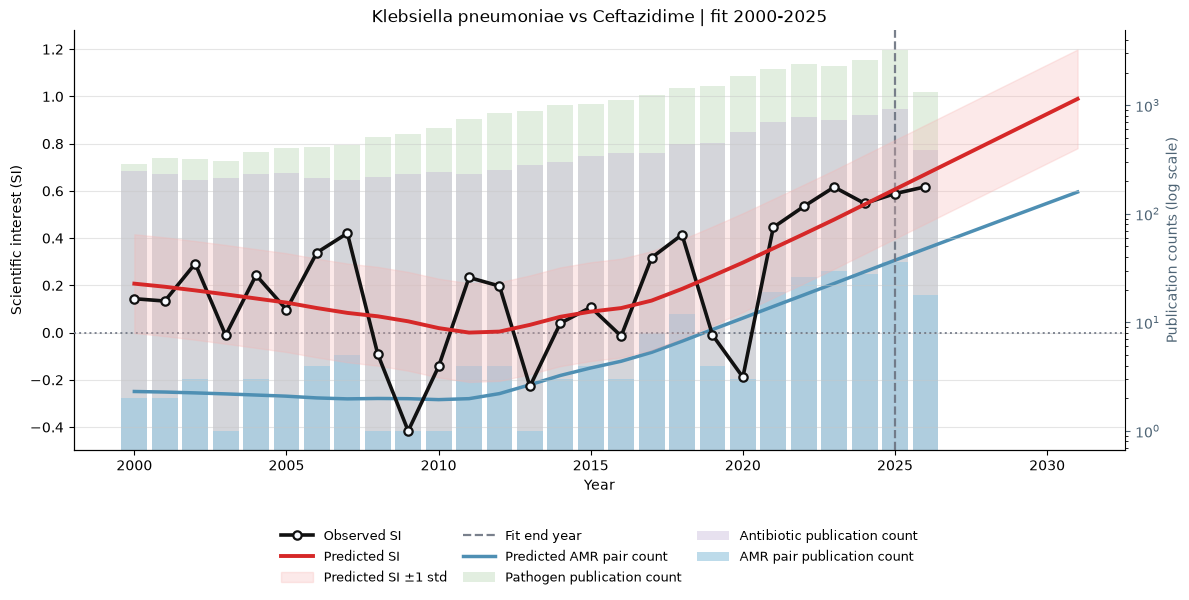

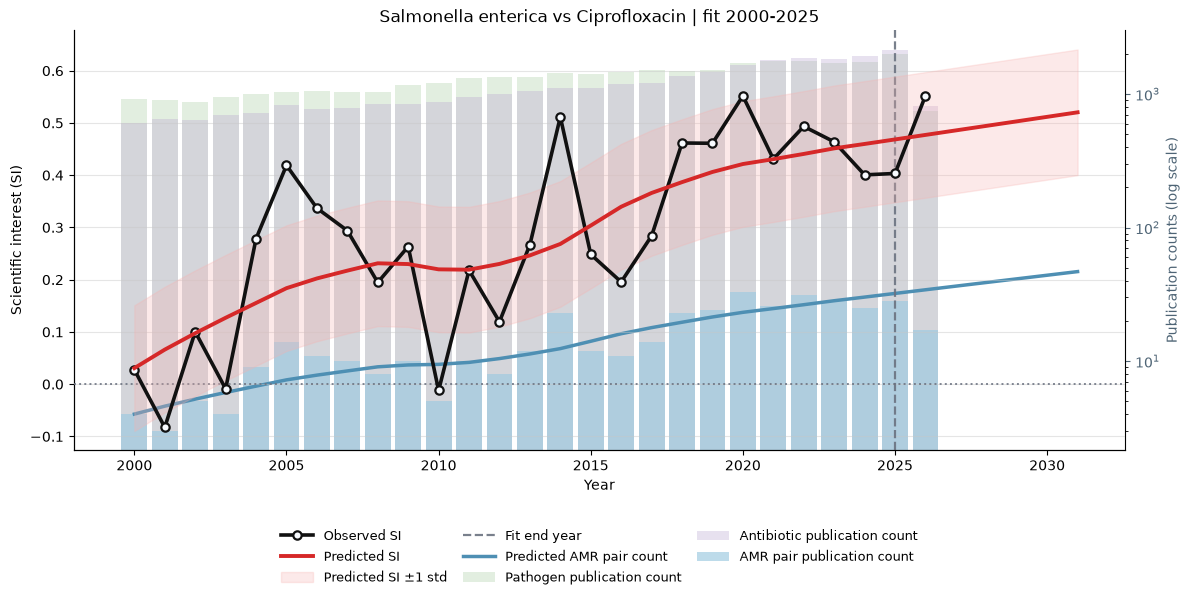

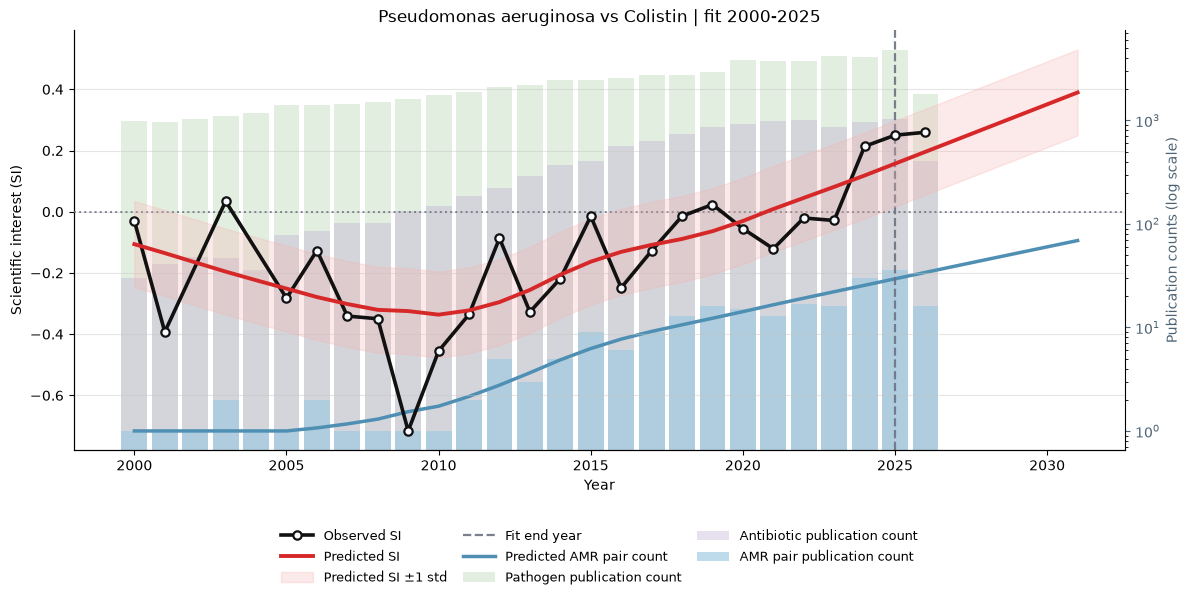

Saved 56 plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/glass_yearly_si_plots
Displayed 10 plots inline.
Saved GLASS SI plots: 56 -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/glass_yearly_si_plots


In [8]:
saved_si_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=glass_plot_pairs_df,
    output_dir=GLASS_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=len(glass_plot_pairs_df),
    loess_frac=LOESS_FRAC,
    loess_degree=LOESS_DEGREE,
    tail_damping_years=TAIL_DAMPING_YEARS,
    min_amr_pair_publication_count=MIN_AMR_PAIR_PUBLICATION_COUNT,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)

print(f"Saved GLASS SI plots: {saved_si_plots:,} -> {GLASS_SI_PLOT_DIR}")